# Notebook 9 – Data Transformation

### Why Transform Data?

Data Transformation is the process of converting data from its original format, structure, or representation into a suitable format for data analysis and machine learning.

Raw data may contain different scales, formats, distributions, and representations. Data transformation helps make the data more consistent, meaningful, and suitable for further processing.

Why Do We Transform Data?

There are several important reasons:

1. To Bring Features to a Similar Scale
2. 
Different features may have different measurement ranges.

Example:

- Age: 20–60
- Salary: 20,000–1,00,000
- Experience: 1–20
  
Scaling helps prevent large numerical values from dominating certain machine learning algorithms

2. To Improve Model Performance
   
Some machine learning algorithms perform better when numerical features are transformed into suitable scales.

Examples:

- Logistic Regression
- K-Nearest Neighbors (KNN)
- Support Vector Machines (SVM)
- K-Means Clustering
  
3. To Reduce Skewness
   
Some numerical features may have highly skewed distributions.

Example: Customer income may contain a few extremely high values.

Log transformation can help reduce right skewness

4. To Handle Different Data Distributions
   
Data may not follow a normal distribution.

Transformations such as:

- Log Transformation
- Square Root Transformation
- Box-Cox Transformation
- Yeo-Johnson Transformation
  
can help make distributions more suitable for particular analyses or models

5. To Convert Categorical Data into Numerical Data
   
Machine learning algorithms generally require numerical inputs.

Example:

Gender	Encoded Value
Male	0
Female	1

Techniques

- Label Encoding
- One-Hot Encoding
- Ordinal Encoding
- Target Encoding
  
6. To Improve Data Interpretability
   
Transformation can make certain relationships easier to analyze and interpret

8. To Prepare Data for Machine Learning
   
Data transformation prepares features in a format that machine learning algorithms can process effectively.

In [ ]:
Real-World Business Example:
    
Scenario: Customer Salary Prediction

A company wants to predict customer purchasing behavior using machine learning.

Original dataset:
    
Customer	Age	Salary	Spending Score
C101	     25	25000	40
C102	     30	50000	60
C103	     35	75000	80
C104	     40	100000	90

Problems:

- Features have different numerical ranges.
- Numerical values may have different distributions.
- Categorical features may need encoding.
- Some features may contain skewness.

In [1]:
import pandas as pd
from sklearn.preprocessing import (
    StandardScaler,
    MinMaxScaler,
    RobustScaler
)

# Create dataset
df = pd.DataFrame({
    'Age': [25, 30, 35, 40, 45],
    'Salary': [25000, 50000, 75000, 100000, 125000],
    'Experience': [2, 5, 10, 15, 20]
})

print("Original Data:")
print(df)

# Standard Scaling
standard = StandardScaler()
standard_data = standard.fit_transform(df)

# Min-Max Scaling
minmax = MinMaxScaler()
minmax_data = minmax.fit_transform(df)

# Robust Scaling
robust = RobustScaler()
robust_data = robust.fit_transform(df)

print("\nStandard Scaled Data:")
print(pd.DataFrame(standard_data, columns=df.columns))

print("\nMin-Max Scaled Data:")
print(pd.DataFrame(minmax_data, columns=df.columns))

print("\nRobust Scaled Data:")
print(pd.DataFrame(robust_data, columns=df.columns))

Original Data:
   Age  Salary  Experience
0   25   25000           2
1   30   50000           5
2   35   75000          10
3   40  100000          15
4   45  125000          20

Standard Scaled Data:
        Age    Salary  Experience
0 -1.414214 -1.414214   -1.286384
1 -0.707107 -0.707107   -0.826961
2  0.000000  0.000000   -0.061256
3  0.707107  0.707107    0.704448
4  1.414214  1.414214    1.470153

Min-Max Scaled Data:
    Age  Salary  Experience
0  0.00    0.00    0.000000
1  0.25    0.25    0.166667
2  0.50    0.50    0.444444
3  0.75    0.75    0.722222
4  1.00    1.00    1.000000

Robust Scaled Data:
   Age  Salary  Experience
0 -1.0    -1.0        -0.8
1 -0.5    -0.5        -0.5
2  0.0     0.0         0.0
3  0.5     0.5         0.5
4  1.0     1.0         1.0


Benefits of Data Transformation:

1. Improves data consistency.
2. Makes features comparable.
3. Helps algorithms that are sensitive to feature scales.
4. Reduces skewness when appropriate.
5. Converts categorical features into numerical representations.
6. Can improve model convergence.
7. Makes data suitable for machine learning pipelines.

Where Does Data Transformation Fit in an ML Pipeline?

Raw Data

Data Cleaning

Data Transformation

Encoding • Scaling • Log Transformation

Feature Selection

Model Training

Model Evaluation

Conclusion:
Data transformation converts raw data into a suitable representation for analysis and machine learning. It helps handle different scales, categorical values, and skewed distributions, making data more useful for building reliable machine learning models.

### Log Transformation


Log Transformation is a mathematical data transformation technique that applies a logarithmic function to numerical feature values to reduce skewness and make highly skewed data more suitable for statistical analysis and machine learning.

It is commonly used when numerical data contains:
- Highly skewed distributions.
- Large differences between values.
- A few extremely large values.
- Right-skewed numerical features.

##### Mathematical Concept

The Log Transformation formula is:

$$
X_{\text{transformed}} = \log(X)
$$

For data containing zero values, we commonly use:

$$
X_{\text{transformed}} = \log(1+X)
$$

This is also called Log1p Transformation

Where:

- $X$ = Original feature value.
- $\log(X)$ = Natural logarithm of the value.
- $X_{\text{transformed}}$ = Transformed feature value.
- $1$ = Added to handle zero values.

Why Do We Use Log Transformation?

1. Reduce Right Skewness: Helps reduce positive skewness in numerical features.
2. Reduce the Impact of Large Values: Compresses the range of large numerical values.
3. Improve Data Distribution: Can make highly skewed data more suitable for statistical analysis.
4. Improve Model Performance: May improve models when relationships are nonlinear or multiplicative.
5. Improve Interpretability: Can make multiplicative relationships easier to analyze.

In [2]:
import pandas as pd
import numpy as np

# Create dataset
df = pd.DataFrame({
    'Customer': ['C101', 'C102', 'C103', 'C104', 'C105'],
    'Income': [10000, 20000, 30000, 50000, 500000]
})

# Display original data
print("Original Data:")
print(df)

# Apply Log Transformation
df['Log_Income'] = np.log1p(df['Income'])

# Display transformed data
print("\nLog Transformed Data:")
print(df)

# Calculate skewness
print("\nOriginal Skewness:")
print(df['Income'].skew())

print("\nTransformed Skewness:")
print(df['Log_Income'].skew())

Original Data:
  Customer  Income
0     C101   10000
1     C102   20000
2     C103   30000
3     C104   50000
4     C105  500000

Log Transformed Data:
  Customer  Income  Log_Income
0     C101   10000    9.210440
1     C102   20000    9.903538
2     C103   30000   10.308986
3     C104   50000   10.819798
4     C105  500000   13.122365

Original Skewness:
2.2091079511423946

Transformed Skewness:
1.3927303057656122


In [ ]:
Advantages and Disadvantages: 

Advantages	                                Disadvantages

Reduces right skewness	                       Not suitable directly for negative values
Compresses large values	                      changes the original scale
Reduces the influence of extreme magnitudes	   Interpretation becomes less direct
Can improve model performance	               May not help every dataset

Important Points

- Log transformation is especially useful for right-skewed data.
- Use np.log1p() when values include zero.
- Use np.log() when all values are positive.
- Check skewness before and after transformation.
- Do not assume log transformation always improves model performance.
- Fit transformations appropriately within the training pipeline to prevent data leakage.

### Square Root Transformation


Square Root Transformation is a mathematical data transformation technique that applies the square root function to numerical feature values to reduce positive skewness and make the data distribution more suitable for statistical analysis and machine learning

It is commonly used when:

- Data contains moderate right skewness.
- Numerical values are non-negative.
- Data contains count-based values.
- Large values need to be compressed.


##### Mathematical Concept

The Square Root Transformation formula is:

$$
X_{\text{transformed}} = \sqrt{X}
$$

For data containing zero values, the same formula can be used:

$$
X_{\text{transformed}} = \sqrt{X}
$$

Where:

- $X$ = Original feature value.
- $\sqrt{X}$ = Square root of the original value.
- $X_{\text{transformed}}$ = Transformed feature value.

**Note:** Square Root Transformation works directly with non-negative values. Negative values require an appropriate alternative or transformation.

Why Do We Use Square Root Transformation?

1. Reduce Skewness: Helps reduce moderate positive skewness.
2. Compress Large Values: Reduces the numerical differences between larger values.
3. Improve Data Distribution: Can make some numerical distributions more suitable for analysis.
4. Handle Count Data: Commonly used for customer purchases, website visits, and transaction counts.
5. Improve Model Performance: May improve model performance when the transformed relationship better matches model assumptions.

In [1]:
import pandas as pd
import numpy as np

# Create dataset
df = pd.DataFrame({
    'Customer': ['C101', 'C102', 'C103', 'C104', 'C105'],
    'Products_Purchased': [4, 9, 16, 25, 100]
})

# Display original data
print("Original Data:")
print(df)

# Apply Square Root Transformation
df['Sqrt_Transformed'] = np.sqrt(df['Products_Purchased'])

# Display transformed data
print("\nSquare Root Transformed Data:")
print(df)

# Calculate skewness
print("\nOriginal Skewness:")
print(df['Products_Purchased'].skew())

print("\nTransformed Skewness:")
print(df['Sqrt_Transformed'].skew())

Original Data:
  Customer  Products_Purchased
0     C101                   4
1     C102                   9
2     C103                  16
3     C104                  25
4     C105                 100

Square Root Transformed Data:
  Customer  Products_Purchased  Sqrt_Transformed
0     C101                   4               2.0
1     C102                   9               3.0
2     C103                  16               4.0
3     C104                  25               5.0
4     C105                 100              10.0

Original Skewness:
2.019941794868532

Transformed Skewness:
1.5491313812566696


In [ ]:
Advantages:

Advantages                                    Disadvantages

Reduces moderate right skewness	     Cannot directly handle negative values

Easy to implement	                 Less effective for highly skewed data

Compresses large values	             Changes the original data scale

Useful for count data	             Does not guarantee a normal distribution


Important Points:

- Square Root Transformation is useful for non-negative numerical data.
- It is commonly applied to count-based features.
- It can reduce moderate right skewness.
- Always compare skewness before and after transformation.
- It does not remove outliers.

### Power Transformation


Power Transformation is a mathematical data transformation technique that applies a mathematical power function to numerical feature values to reduce skewness, stabilize variance, and make data distributions more suitable for statistical analysis and machine learning.

It is commonly used when:

- Data contains highly skewed distributions.
- Numerical features have different distribution shapes.
- Variance increases with the magnitude of values.
- Data needs to be transformed to better satisfy statistical assumptions
  
Two commonly used Power Transformation techniques are:

1. Box-Cox Transformation
2. Yeo-Johnson Transformation


##### Mathematical Concept

The general Power Transformation can be represented as:

$$
X_{\text{transformed}} = X^\lambda
$$

Where:

- $X$ = Original feature value.
- $\lambda$ = Power transformation parameter.
- $X_{\text{transformed}}$ = Transformed feature value.

The parameter $\lambda$ determines how the original values are transformed.

##### Common Power Values

| Power ($\lambda$) | Transformation |
|---|---|
| 2 | Square Transformation |
| 1 | No transformation |
| 0.5 | Square Root Transformation |
| 0 | Log Transformation (limiting case for positive values) |
| -1 | Reciprocal Transformation |


Why Do We Use Power Transformation?

1. Reduce Skewness: Helps make highly skewed data more symmetric.
2. Stabilize Variance: Helps reduce changes in variance across different values.
3. Improve Data Distribution: Makes data more suitable for statistical analysis.
4. Improve Model Performance: Can improve models when their assumptions are better satisfied.
5. Handle Nonlinear Relationships: Can make some relationships easier to model.

In [2]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import PowerTransformer

# Create dataset
df = pd.DataFrame({
    'Income': [10000, 12000, 15000, 20000, 25000,
               30000, 50000, 100000, 200000, 500000]
})

# Display original data
print("Original Data:")
print(df)

# Create Power Transformer
pt = PowerTransformer(method='yeo-johnson')

# Apply Power Transformation
df['Transformed_Income'] = pt.fit_transform(df[['Income']])

# Display transformed data
print("\nPower Transformed Data:")
print(df)

# Calculate skewness
print("\nOriginal Skewness:")
print(df['Income'].skew())

print("\nTransformed Skewness:")
print(df['Transformed_Income'].skew())

# Display lambda value
print("\nLambda Value:")
print(pt.lambdas_)

Original Data:
   Income
0   10000
1   12000
2   15000
3   20000
4   25000
5   30000
6   50000
7  100000
8  200000
9  500000

Power Transformed Data:
   Income  Transformed_Income
0   10000           -1.451481
1   12000           -1.175221
2   15000           -0.863303
3   20000           -0.499994
4   25000           -0.245508
5   30000           -0.053733
6   50000            0.414989
7  100000            0.916101
8  200000            1.296285
9  500000            1.661866

Original Skewness:
2.452444595685283

Transformed Skewness:
0.25421930296464595

Lambda Value:
[-0.39844857]


Types of Power Transformation:

1. Box-Cox Transformation
   
- Works only with strictly positive values.
- Uses a parameter called lambda.
- Helps reduce skewness
  
2. Yeo-Johnson Transformation
   
- Supports positive values.
- Supports zero values.
- Supports negative values.
- Helps reduce skewness.

In [ ]:
Advantages and Disadvantages:

Advantages	                    Disadvantages
Reduces skewness	            Changes the original scale
Stabilizes variance	            Lambda selection is required
Supports statistical analysis	Interpretation becomes less direct
Can improve model performance	Does not guarantee normality

Important Points:
    
- Power Transformation is useful for skewed numerical features.
- Box-Cox requires strictly positive values.
- Yeo-Johnson supports negative, zero, and positive values.
- The lambda parameter controls the transformation.
- Always compare the distributions before and after transformation.
- Fit the transformer on training data and apply it to test data to avoid data leakage.

### Box-Cox Transformation


Box-Cox Transformation is a statistical data transformation technique used to reduce skewness and stabilize variance in numerical data by applying a power transformation.

It helps make highly skewed data more symmetric and suitable for statistical analysis and machine learning.

It is commonly used when:

- Data contains positive numerical values.
- Data has right skewness.
- Variance is not constant.
- Statistical analysis requires approximately normal data.


##### Mathematical Concept

The Box-Cox Transformation formula is:

For $\lambda \neq 0$:

$$
X_{\text{transformed}} = \frac{X^\lambda - 1}{\lambda}
$$

For $\lambda = 0$:

$$
X_{\text{transformed}} = \ln(X)
$$

Where:

- $X$ = Original feature value.
- $\lambda$ = Power transformation parameter.
- $X_{\text{transformed}}$ = Transformed feature value.
- $\ln(X)$ = Natural logarithm of the original value.

**Note:** Box-Cox Transformation requires all input values to be strictly positive ($X > 0$).


Why Do We Use Box-Cox Transformation?

1. Reduces positive skewness.
2. Stabilizes variance.
3. Makes distributions more symmetric.
4. Helps satisfy statistical assumptions.
5. Can improve the performance of models that benefit from transformed features.

In [3]:
import pandas as pd
from sklearn.preprocessing import PowerTransformer

# Create dataset
df = pd.DataFrame({
    'Income': [
        10000, 12000, 15000, 20000, 25000,
        30000, 50000, 100000, 200000, 500000
    ]
})

# Display original data
print("Original Data:")
print(df)

# Create Box-Cox Transformer
pt = PowerTransformer(method='box-cox')

# Apply transformation
df['BoxCox_Income'] = pt.fit_transform(df[['Income']])

# Display transformed data
print("\nBox-Cox Transformed Data:")
print(df)

# Compare skewness
print("\nOriginal Skewness:")
print(df['Income'].skew())

print("\nTransformed Skewness:")
print(df['BoxCox_Income'].skew())

# Display estimated lambda
print("\nLambda Value:")
print(pt.lambdas_)

Original Data:
   Income
0   10000
1   12000
2   15000
3   20000
4   25000
5   30000
6   50000
7  100000
8  200000
9  500000

Box-Cox Transformed Data:
   Income  BoxCox_Income
0   10000      -1.451496
1   12000      -1.175224
2   15000      -0.863298
3   20000      -0.499985
4   25000      -0.245500
5   30000      -0.053726
6   50000       0.414990
7  100000       0.916096
8  200000       1.296279
9  500000       1.661865

Original Skewness:
2.452444595685283

Transformed Skewness:
0.25420316103432133

Lambda Value:
[-0.39842038]


In [ ]:
Advantages and Disadvantages:

Advantages	                        Disadvantages
Reduces skewness	              Requires strictly positive values
Stabilizes variance	              Lambda estimation is required
Makes data more symmetric	      Changes original data scale
Supports statistical analysis	  Does not guarantee normality

 Important Points:
     
- Box-Cox works only with strictly positive values.
- Lambda controls the transformation.
- Lambda is generally estimated from the data.
- Compare skewness before and after transformation.
- Apply the fitted transformation consistently to training and testing data to avoid data leakage.

### Yeo-Johnson Transformation


Yeo-Johnson Transformation is a statistical data transformation technique used to reduce skewness and stabilize variance in numerical data by applying a power transformation.

It is similar to Box-Cox Transformation, but it has an important advantage: it supports positive, zero, and negative values.

It is commonly used when:
- Data contains positive values.
- Data contains zero values.
- Data contains negative values.
- Numerical features have skewed distributions.
- Variance needs to be stabilized.


##### Mathematical Concept

The Yeo-Johnson Transformation formula has two cases.

 Case 1: For $X \geq 0$

When $\lambda \neq 0$:

$$
X_{\text{transformed}} =
\frac{(X+1)^\lambda-1}{\lambda}
$$

When $\lambda = 0$:

$$
X_{\text{transformed}} = \ln(X+1)
$$

Case 2: For $X < 0$

When $\lambda \neq 2$:

$$
X_{\text{transformed}} =
-\frac{(-X+1)^{2-\lambda}-1}{2-\lambda}
$$

When $\lambda = 2$:

$$
X_{\text{transformed}} = -\ln(-X+1)
$$

Where:

- $X$ = Original feature value.
- $\lambda$ = Power transformation parameter.
- $X_{\text{transformed}}$ = Transformed feature value.
- $\ln$ = Natural logarithm.


Why Do We Use Yeo-Johnson Transformation?

1. Reduce Skewness: Helps make skewed distributions more symmetric.
2. Handle Negative Values: Supports negative, zero, and positive numerical values.
3. Stabilize Variance: Can reduce variance changes across different values.
4. Improve Data Distribution: Makes data more suitable for certain statistical methods.
5. Improve Model Performance: Can improve machine learning performance when the transformation better suits the model.

In [4]:
import pandas as pd
from sklearn.preprocessing import PowerTransformer

# Create dataset
df = pd.DataFrame({
    'Income_Difference': [
        -50000, -20000, -10000, -5000,
        0, 10000, 20000, 50000, 100000, 500000
    ]
})

# Display original data
print("Original Data:")
print(df)

# Create Yeo-Johnson Transformer
pt = PowerTransformer(method='yeo-johnson')

# Apply transformation
df['Yeo_Johnson'] = pt.fit_transform(
    df[['Income_Difference']]
)

# Display transformed data
print("\nYeo-Johnson Transformed Data:")
print(df)

# Calculate skewness
print("\nOriginal Skewness:")
print(df['Income_Difference'].skew())

print("\nTransformed Skewness:")
print(df['Yeo_Johnson'].skew())

# Display lambda value
print("\nLambda Value:")
print(pt.lambdas_)

Original Data:
   Income_Difference
0             -50000
1             -20000
2             -10000
3              -5000
4                  0
5              10000
6              20000
7              50000
8             100000
9             500000

Yeo-Johnson Transformed Data:
   Income_Difference  Yeo_Johnson
0             -50000    -2.013352
1             -20000    -0.729761
2             -10000    -0.336504
3              -5000    -0.153165
4                  0     0.006980
5              10000     0.072457
6              20000     0.129093
7              50000     0.285301
8             100000     0.526008
9             500000     2.212944

Original Skewness:
2.8010938309144473

Transformed Skewness:
0.28658760959214324

Lambda Value:
[0.89903669]


In [ ]:
Advantages and Disadvantages:

Advantages	                  Disadvantages

Supports negative values	Changes original data scale
Supports zero values	    Lambda estimation is required
Reduces skewness	        Interpretation becomes less direct
Can stabilize variance	   Does not guarantee normality

Important Points:

- Yeo-Johnson supports negative, zero, and positive values.
- Lambda determines the transformation.
- It is useful for skewed numerical features.
- Compare skewness before and after transformation.
- It does not remove outliers.
- Fit the transformer on training data and apply the same fitted transformation to test data to avoid data leakage.

### Handling Skewed Data

Handling Skewed Data is the process of identifying and managing numerical data that is not symmetrically distributed around its central value.

In a skewed distribution, most observations are concentrated on one side, while a long tail extends towards the other side.

Skewed data can affect statistical analysis, data interpretation, and certain machine learning algorithms.

There are two major types of skewness:

1. Right Skewness (Positive Skewness)
2. Left Skewness (Negative Skewness)


##### Mathematical Concept

Skewness measures the asymmetry of a numerical data distribution.

The population skewness formula is:

$$
\text{Skewness} = \frac{E[(X-\mu)^3]}{\sigma^3}
$$

Where:

- $X$ = Individual data value.
- $\mu$ = Population mean.
- $\sigma$ = Population standard deviation.
- $E$ = Expected value.
- Skewness = Measure of distribution asymmetry.


Why Do We Handle Skewed Data?

1. To improve data distribution.
2. To reduce the influence of extreme values.
3. To improve statistical analysis.
4. To make certain machine learning algorithms perform better.
5. To improve data visualization and interpretation.
6. To satisfy statistical assumptions when required.

Original Skewness:
2.6118898099101178

Transformed Skewness:
0.8200848939681945


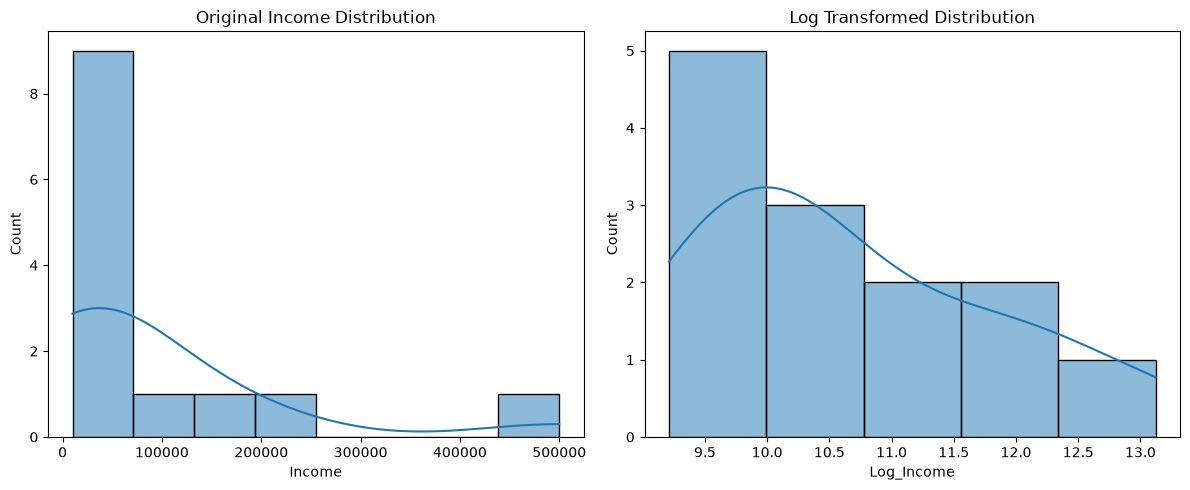

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Create dataset
df = pd.DataFrame({
    'Income': [
        10000, 12000, 15000, 18000, 20000,
        25000, 30000, 35000, 50000, 100000,
        150000, 200000, 500000
    ]
})

# Original skewness
print("Original Skewness:")
print(df['Income'].skew())

# Apply Log Transformation
df['Log_Income'] = np.log1p(df['Income'])

# Transformed skewness
print("\nTransformed Skewness:")
print(df['Log_Income'].skew())

# Visualize distributions
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(df['Income'], kde=True)
plt.title("Original Income Distribution")

plt.subplot(1, 2, 2)
sns.histplot(df['Log_Income'], kde=True)
plt.title("Log Transformed Distribution")

plt.tight_layout()
plt.show()

Important Points:

- Identify skewness before applying transformations.
- Check the distribution using histograms and box plots.
- Select a transformation based on the data.
- Compare skewness before and after transformation.
- Do not remove genuine extreme values without investigation.
- Apply transformations consistently to training and testing data.
- Skewness reduction does not automatically guarantee better model performance.

Conclusion:

Handling skewed data is an important part of data preprocessing. It helps us understand asymmetric distributions and select suitable transformation techniques to prepare numerical features for statistical analysis and machine learning.

### Normalization


Normalization is a data transformation technique used to convert numerical data into a common scale without changing the relative relationships between the original values.

It transforms numerical feature values into a specified range, commonly between 0 and 1.

Normalization is performed during data preprocessing to make numerical features comparable and suitable for Machine Learning algorithms.


##### Mathematical Concept

Min-Max Normalization transforms each numerical value using the following formula:

$$
X_{\text{normalized}} = \frac{X-X_{\min}}{X_{\max}-X_{\min}}
$$

Where:

- $X$ = Original feature value.
- $X_{\min}$ = Minimum value of the feature.
- $X_{\max}$ = Maximum value of the feature.
- $X_{\text{normalized}}$ = Normalized value.

The normalized values generally fall within:

$$
0 \leq X_{\text{normalized}} \leq 1
$$


In [6]:

# Import libraries
import pandas as pd
from sklearn.preprocessing import MinMaxScaler

# Create dataset
data = {
    'Age': [20, 25, 30, 35, 40],
    'Salary': [20000, 30000, 50000, 80000, 100000],
    'Experience': [1, 2, 5, 8, 10]
}

df = pd.DataFrame(data)

print("Original Dataset:")
print(df)

# Create MinMaxScaler object
scaler = MinMaxScaler()

# Apply Normalization
normalized_data = scaler.fit_transform(df)

# Convert normalized data into DataFrame
normalized_df = pd.DataFrame(
    normalized_data,
    columns=df.columns
)

print("\nNormalized Dataset:")
print(normalized_df)

# Display minimum and maximum values
print("\nMinimum Values:")
print(normalized_df.min())

print("\nMaximum Values:")
print(normalized_df.max())


Original Dataset:
   Age  Salary  Experience
0   20   20000           1
1   25   30000           2
2   30   50000           5
3   35   80000           8
4   40  100000          10

Normalized Dataset:
    Age  Salary  Experience
0  0.00   0.000    0.000000
1  0.25   0.125    0.111111
2  0.50   0.375    0.444444
3  0.75   0.750    0.777778
4  1.00   1.000    1.000000

Minimum Values:
Age           0.0
Salary        0.0
Experience    0.0
dtype: float64

Maximum Values:
Age           1.0
Salary        1.0
Experience    1.0
dtype: float64


Why Normalization Is Used in Data Transformation
1. To bring numerical features into a common scale.
2. To reduce the influence of differences in feature magnitudes.
3. To prepare numerical data for Machine Learning algorithms.
4. To improve distance calculations in KNN and K-Means.
5. To support efficient optimization in neural networks.

Normalization is a numerical data transformation technique.
It commonly uses Min-Max Scaling.
It is sensitive to outliers.
It does not remove outliers.
It does not necessarily make data normally distributed.
Apply normalization after splitting training and testing data to avoid data leakage.

### Standardization

Standardization is a data transformation technique used to transform numerical features so that they have a mean of 0 and a standard deviation of 1.

It is also called Z-score Scaling.

Standardization helps Machine Learning algorithms work with numerical features that have different scales


##### Mathematical Concept

The Z-score is calculated using the following formula:

$$
z = \frac{x-\mu}{\sigma}
$$


 Example

Suppose:

- $x = 1.2$
- $\mu = 0$
- $\sigma = 1$

Substituting the values:

$$
z = \frac{1.2-0}{1}
$$

$$
z = 1.2
$$

The corresponding cumulative standard normal probability is:

$$
\Phi(z) \approx 0.8849
$$

$$
\Phi(1.2) \approx 88.49\%
$$

Where:

- $X$ = Original feature value.
- $\mu$ = Mean of the feature.
- $\sigma$ = Standard deviation of the feature.
- $Z$ = Standardized value.
- $\Phi(z)$ = Cumulative probability of the standard normal distribution.

After standardization:

$$
\text{Mean} \approx 0
$$

$$
\text{Standard Deviation} \approx 1
$$


In [8]:

# Import libraries
import pandas as pd
from sklearn.preprocessing import StandardScaler

# Create dataset
data = {
    'Age': [20, 25, 30, 35, 40],
    'Salary': [20000, 30000, 50000, 80000, 100000],
    'Experience': [1, 2, 5, 8, 10]
}

df = pd.DataFrame(data)

print("Original Dataset:")
print(df)

# Create StandardScaler object
scaler = StandardScaler()

# Apply Standardization
standardized_data = scaler.fit_transform(df)

# Convert standardized data into DataFrame
standardized_df = pd.DataFrame(
    standardized_data,
    columns=df.columns
)

print("\nStandardized Dataset:")
print(standardized_df)

# Verify mean and standard deviation
print("\nMean Values:")
print(standardized_df.mean())

print("\nStandard Deviation:")
print(standardized_df.std(ddof=0))


Original Dataset:
   Age  Salary  Experience
0   20   20000           1
1   25   30000           2
2   30   50000           5
3   35   80000           8
4   40  100000          10

Standardized Dataset:
        Age    Salary  Experience
0 -1.414214 -1.197342   -1.224745
1 -0.707107 -0.864747   -0.933139
2  0.000000 -0.199557   -0.058321
3  0.707107  0.798228    0.816497
4  1.414214  1.463418    1.399708

Mean Values:
Age           0.000000e+00
Salary       -8.881784e-17
Experience   -4.440892e-17
dtype: float64

Standard Deviation:
Age           1.0
Salary        1.0
Experience    1.0
dtype: float64


Advantages:

1. Brings numerical features to a common statistical scale.
2. Helps distance-based algorithms.
3. Supports gradient-based optimization.
4. Useful for features with different measurement units.
5. Improves numerical stability in some ML workflows
   
Limitations:

1. Sensitive to outliers.
2. Does not guarantee a normal distribution.
3. Standardized values are not restricted to 0 and 1.
4. Not necessary for every Machine Learning algorithm.

Original and Standardized Data:
   Salary  Standardized_Salary
0   20000            -1.204508
1   25000            -0.985506
2   30000            -0.766505
3   35000            -0.547504
4   40000            -0.328502
5   45000            -0.109501
6   50000             0.109501
7   60000             0.547504
8   70000             0.985506
9  100000             2.299515


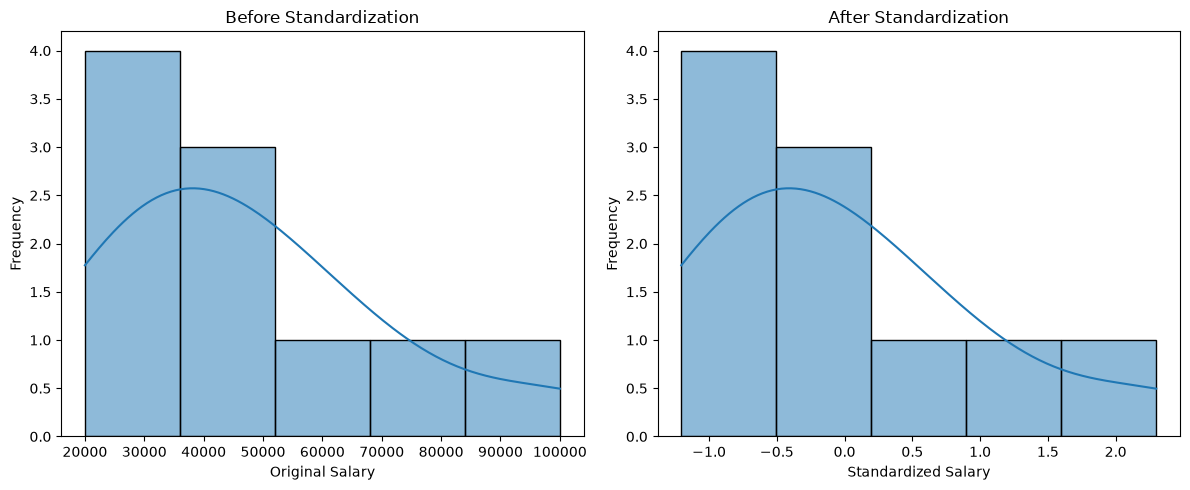


Before Transformation:
count        10.000000
mean      47500.000000
std       24065.881797
min       20000.000000
25%       31250.000000
50%       42500.000000
75%       57500.000000
max      100000.000000
Name: Salary, dtype: float64

After Transformation:
count    1.000000e+01
mean    -4.440892e-17
std      1.054093e+00
min     -1.204508e+00
25%     -7.117547e-01
50%     -2.190014e-01
75%      4.380029e-01
max      2.299515e+00
Name: Standardized_Salary, dtype: float64


In [9]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

# Create dataset
data = {
    'Salary': [20000, 25000, 30000, 35000, 40000,
               45000, 50000, 60000, 70000, 100000]
}

df = pd.DataFrame(data)

# Apply Standardization
scaler = StandardScaler()

df['Standardized_Salary'] = scaler.fit_transform(
    df[['Salary']]
)

# Display original and transformed data
print("Original and Standardized Data:")
print(df)

# Compare distributions
plt.figure(figsize=(12, 5))

# Before transformation
plt.subplot(1, 2, 1)
sns.histplot(df['Salary'], kde=True)
plt.title("Before Standardization")
plt.xlabel("Original Salary")
plt.ylabel("Frequency")

# After transformation
plt.subplot(1, 2, 2)
sns.histplot(df['Standardized_Salary'], kde=True)
plt.title("After Standardization")
plt.xlabel("Standardized Salary")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

# Compare statistical measures
print("\nBefore Transformation:")
print(df['Salary'].describe())

print("\nAfter Transformation:")
print(df['Standardized_Salary'].describe())
